In [3]:
import re
import numpy as np

def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts the first 5 columns: epsilon, p_star, uncertainty, s_hat, n_shots

    Returns:
        epsilon      : np.ndarray
        p_star       : np.ndarray
        uncertainty  : np.ndarray
        s_hat        : np.ndarray
        n_shots      : np.ndarray (int)
    """
    epsilons      = []
    p_stars       = []
    uncertainties = []
    s_hats        = []
    n_shots       = []

    with open(filepath, "r", encoding="utf-8", errors="replace") as f:  # ← fix here
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        # ── Detect start of data section ──────────────────────────────────────
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue  # skip the header row

        # ── Skip separator line ───────────────────────────────────────────────
        if in_data_section and set(line) <= set("-"):
            continue

        # ── Parse data rows ───────────────────────────────────────────────────
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))
            uncertainties.append(float(parts[2]))
            s_hats.append(float(parts[3]))
            n_shots.append(int(parts[4]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        np.array(uncertainties),
        np.array(s_hats),
        np.array(n_shots),
    )


# ── Usage ─────────────────────────────────────────────────────────────────────
ALPHA = 0.05
epsilon, p_star, p_uncertainty, s_hat, n_shots = parse_iqae_ceiling_file(
    "adaptive_searchCP_Nmax, a = 0.3.txt"
)

Exact simulation again, but this time only obtaining the internal log schedule according to the parameter obtained by the search algorithm.

In [41]:
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES — imports, problem definition, noise model, N_max
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

from qiskit.circuit import QuantumCircuit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

# ── Fixed experiment parameters ────────────────────────────────────────────────
p_true = 0.8 ################################################################################
ALPHA  = 0.05
N_JOBS = 18


# ── Bernoulli amplitude estimation problem ─────────────────────────────────────
class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k


problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")


# ── Noise model builder ────────────────────────────────────────────────────────
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error: λ ∈ [0, 1] is the
# physically meaningful range (λ=1 is full depolarization).
MAX_DEPOL_LAMBDA = 1.0          # λ ≤ 1: physically meaningful range

def build_noisy_sampler(lambda_depol, n_shots):
    if lambda_depol > 0.0:
        lam = min(lambda_depol, MAX_DEPOL_LAMBDA)
        error_1q = depolarizing_error(lam, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler


# ── Ceiling N_max ──────────────────────────────────────────────────────────────
# Rounds down to prevent from overshooting the theoretical limit
def N_max_Chernoff(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

def N_max_CP(epsilon, alpha):
    raw = 69 * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

print("Prerequisites loaded ✅")

All imports OK ✅
Problem defined ✅
Prerequisites loaded ✅


In [42]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL A
# ══════════════════════════════════════════════════════════════════════════════
def _safe_float(x):
    return float(x) if x is not None else None

def _safe_list(x):
    return list(x) if x is not None else None

def _safe_list_of_lists(x):
    return [list(item) for item in x] if x is not None else None

def _safe_delta_theta_list(theta_intervals):
    """
    Compute Δθ_t = θ_hi - θ_lo for every round t = 1 … T.
    Returns a list of floats (one per round), or None if unavailable.
    Malformed individual rounds are stored as None to preserve indexing.
    """
    if theta_intervals is None or len(theta_intervals) == 0:
        return None
    result = []
    for interval in theta_intervals:
        if interval is not None and len(interval) == 2:
            result.append(float(interval[1] - interval[0]))
        else:
            result.append(None)   # malformed round — keep slot
    return result


def single_diag_run_full(eps, p_noise, n_shots):
    """
    One IQAE run at (eps, p_noise) with shot budget n_shots.
    Captures the full IterativeAmplitudeEstimationResult, excluding
    circuit_results (raw statevector/counts — not needed here).
    Each field is converted defensively so a single None/missing field
    doesn't discard the whole run.
    """
    try:
        sampler = build_noisy_sampler(p_noise, n_shots)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
            confint_method = "beta",  # chernoff or beta (CH or CP)
        )
        result = iae.estimate(problem)

        powers   = list(result.powers) if result.powers is not None else []
        K_values = [2 * k + 1 for k in powers]

        estimate = _safe_float(result.estimation_processed)
        success  = int(estimate is not None and abs(estimate - p_true) <= eps)

        # ── theta intervals — build once, derive delta_theta from it ──────────
        theta_intervals    = _safe_list_of_lists(result.theta_intervals)
        delta_theta_list   = _safe_delta_theta_list(theta_intervals)

        return {
            "success"                      : success,
            "powers"                       : powers,
            "K_values"                     : K_values,
            "T_eps"                        : len(powers),
            "max_K"                        : max(K_values) if K_values else None,
            "sum_K"                        : sum(K_values) if K_values else None,

            # amplitude-domain results
            "estimation"                   : estimate,
            "signed_error"                 : (estimate - p_true) if estimate is not None else None,
            "confidence_interval"          : _safe_list(result.confidence_interval),
            "confidence_interval_processed": _safe_list(result.confidence_interval_processed),
            "estimate_intervals"           : _safe_list_of_lists(result.estimate_intervals),

            # angle-domain results
            "theta_intervals"              : theta_intervals,
            "delta_theta_list"             : delta_theta_list,              # NEW: [Δθ_1, …, Δθ_T]

            # schedule / information mechanics
            "ratios"                       : _safe_list(result.ratios),
            "num_oracle_queries"           : int(result.num_oracle_queries) if result.num_oracle_queries is not None else None,

            # precision bookkeeping
            "epsilon_target"               : _safe_float(result.epsilon_target),
            "epsilon_estimated"            : _safe_float(result.epsilon_estimated),
            "epsilon_estimated_processed"  : _safe_float(result.epsilon_estimated_processed),
            "alpha_echo"                   : _safe_float(result.alpha),

            # sampling bookkeeping
            "shots"                        : result.shots,
            "n_shots_requested"            : n_shots,

            "error_message"                : None,
        }

    except Exception as e:
        err_str = f"{type(e).__name__}: {e}"
        print(f"[WARN] single_diag_run_full failed: {err_str}")
        return {
            "success": 0, "powers": [], "K_values": [], "T_eps": 0,
            "max_K": None, "sum_K": None,
            "estimation": None, "signed_error": None,
            "confidence_interval": None, "confidence_interval_processed": None,
            "estimate_intervals": None,
            "theta_intervals"              : None,
            "delta_theta_list"             : None,                          # NEW
            "ratios": None, "num_oracle_queries": None,
            "epsilon_target": eps, "epsilon_estimated": None,
            "epsilon_estimated_processed": None, "alpha_echo": ALPHA,
            "shots": None, "n_shots_requested": n_shots,
            "error_message": err_str,
        }

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL B  - Simulation sweep: run R runs per (ε, p*) point, collect full results
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from joblib import Parallel, delayed
import numpy as np

R = 1000   # runs per point

diag_results = []

for eps, p_star_val in zip(epsilon, p_star):
    n_shots_diag = int(N_max_CP(eps, ALPHA))   # ← Cp or CH

    print(f"\n{'─'*60}")
    print(f"ε={eps:.6f} | p*={p_star_val:.6f} | N_shots={n_shots_diag} "
          f"| running {R} runs ...")

    runs = Parallel(n_jobs=N_JOBS)(
        delayed(single_diag_run_full)(eps, p_star_val, n_shots_diag)
        for _ in range(R)
    )

    # ── Live per-run schedule output ──────────────────────────────────────────
    for i, run in enumerate(runs):
        if run["error_message"] is not None:
            print(f"  run {i+1:>3} | ERROR: {run['error_message']}")
            continue

        status  = "✅" if run["success"] else "❌"
        err_str = f"{run['signed_error']:.6f}" if run["signed_error"] is not None else "N/A"

        # final Δθ — last element of the stored list
        dtl     = run.get("delta_theta_list")
        dth_str = f"{dtl[-1]:.6f}" if (dtl and dtl[-1] is not None) else "N/A"

        print(f"  run {i+1:>3} | {status} | T={run['T_eps']:>2} | "
              f"K_values={run['K_values']} | signed_error={err_str} | "
              f"Δθ_final={dth_str} | Δθ_seq={dtl}")

    # ── Aggregate ─────────────────────────────────────────────────────────────
    valid_runs   = [r for r in runs if r["T_eps"] > 0]
    success_rate = np.mean([r["success"] for r in runs])

    T_values    = [r["T_eps"] for r in valid_runs]
    maxK_values = [r["max_K"] for r in valid_runs]
    sumK_values = [r["sum_K"] for r in valid_runs]
    err_values  = [r["signed_error"] for r in valid_runs
                   if r["signed_error"] is not None]

    # ── delta_theta aggregation — from delta_theta_list ───────────────────────
    # final Δθ per run (last element of each run's list)
    dtheta_final_values = [
        r["delta_theta_list"][-1]
        for r in valid_runs
        if r.get("delta_theta_list") and r["delta_theta_list"][-1] is not None
    ]

    # full Δθ sequences — one list per run (for downstream convergence plots)
    dtheta_sequences = [
        r["delta_theta_list"]
        for r in valid_runs
        if r.get("delta_theta_list") is not None
    ]

    schedule_counts = Counter(tuple(r["K_values"]) for r in valid_runs)
    most_common_schedule, most_common_count = (
        schedule_counts.most_common(1)[0] if schedule_counts else ((), 0)
    )

    diag_results.append({
        "epsilon"              : eps,
        "p_star"               : p_star_val,
        "n_shots"              : n_shots_diag,
        "success_rate"         : success_rate,
        "T_mean"               : float(np.mean(T_values))    if T_values    else None,
        "T_std"                : float(np.std(T_values))     if T_values    else None,
        "max_K_mean"           : float(np.mean(maxK_values)) if maxK_values else None,
        "sum_K_mean"           : float(np.mean(sumK_values)) if sumK_values else None,
        "mean_signed_error"    : float(np.mean(err_values))  if err_values  else None,
        # ── Δθ final (scalar summary) ─────────────────────────────────────────
        "delta_theta_mean"     : float(np.mean(dtheta_final_values))   if dtheta_final_values else None,
        "delta_theta_std"      : float(np.std(dtheta_final_values))    if dtheta_final_values else None,
        "delta_theta_median"   : float(np.median(dtheta_final_values)) if dtheta_final_values else None,
        "n_dtheta_collected"   : len(dtheta_final_values),
        # ── Δθ sequences (full per-round lists) ──────────────────────────────
        "delta_theta_sequences": dtheta_sequences,   # list of lists — one per valid run
        # ─────────────────────────────────────────────────────────────────────
        "most_common_schedule" : list(most_common_schedule),
        "most_common_count"    : most_common_count,
        "n_valid_runs"         : len(valid_runs),
        "raw_runs"             : runs,
    })

    print(f"  → success_rate={success_rate:.3f} | "
          f"Δθ_final mean={diag_results[-1]['delta_theta_mean']:.6f} ± "
          f"{diag_results[-1]['delta_theta_std']:.6f} | "
          f"most_common_schedule={list(most_common_schedule)} "
          f"({most_common_count}/{len(valid_runs)})")

print("\n✅ Full diagnostic sweep complete.")


────────────────────────────────────────────────────────────
ε=0.000100 | p*=0.125000 | N_shots=431 | running 1000 runs ...
  run   1 | ❌ | T= 5 | K_values=[1, 1, 7, 69, 755] | signed_error=-0.023694 | Δθ_final=0.000030 | Δθ_seq=[0.25, 0.022526896184745265, 0.003244941002255558, 0.00032607326907094225, 3.0017388386982535e-05]
  run   2 | ✅ | T= 6 | K_values=[1, 1, 5, 39, 399, 4285] | signed_error=0.000016 | Δθ_final=0.000005 | Δθ_seq=[0.25, 0.022537529012156332, 0.004496038205567349, 0.0005763832676326242, 5.662808234108141e-05, 5.2707580925071e-06]
  run   3 | ✅ | T= 6 | K_values=[1, 1, 5, 49, 509, 5621] | signed_error=-0.000011 | Δθ_final=0.000004 | Δθ_seq=[0.25, 0.02253882151329023, 0.004495789487534596, 0.000458748906830897, 4.435081412751396e-05, 4.039953465567736e-06]
  run   4 | ✅ | T= 6 | K_values=[1, 1, 5, 43, 429, 4701] | signed_error=0.000004 | Δθ_final=0.000005 | Δθ_seq=[0.25, 0.022527994370935694, 0.004496500436988793, 0.0005240416432142625, 5.245111759799581e-05, 4.78300

KeyboardInterrupt: 

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL C  (updated — uses delta_theta_list from Cell A)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np

eps_out              = []
p_star_out           = []
T_out                = []
K_values_out         = []
ratios_out           = []
success_out          = []
n_shots_diag_out     = []
signed_error_out     = []   # per-run signed error        (None if unavailable)
error_message_out    = []   # per-run error message       (None if clean run)
delta_theta_out      = []   # final Δθ per run            (None if unavailable)
delta_theta_list_out = []   # full Δθ sequence per run    (None if unavailable)

# ── Flatten all runs across all epsilon points ────────────────────────────────
for point in diag_results:
    eps_val          = point["epsilon"]
    p_star_val       = point["p_star"]
    n_shots_diag_val = point["n_shots"]

    for run in point["raw_runs"]:
        eps_out.append(eps_val)
        p_star_out.append(p_star_val)
        T_out.append(run["T_eps"])
        K_values_out.append(run["K_values"])
        ratios_out.append(run["ratios"])
        success_out.append(bool(run["success"]))
        n_shots_diag_out.append(n_shots_diag_val)
        signed_error_out.append(run.get("signed_error"))       # None if errored
        error_message_out.append(run.get("error_message"))     # None if clean

        # ── Δθ — read directly from Cell A's stored list ─────────────────────
        dtl = run.get("delta_theta_list")
        delta_theta_list_out.append(dtl)                       # full sequence or None
        delta_theta_out.append(
            dtl[-1] if (dtl and dtl[-1] is not None) else None # final value  or None
        )

# ── Convert to numpy arrays ───────────────────────────────────────────────────
eps_arr              = np.array(eps_out)
p_star_arr           = np.array(p_star_out)
T_arr                = np.array(T_out)
K_values_arr         = np.array(K_values_out,          dtype=object)  # ragged
ratios_arr           = np.array(ratios_out,             dtype=object)  # ragged
success_arr          = np.array(success_out,            dtype=bool)
n_shots_diag_arr     = np.array(n_shots_diag_out,       dtype=int)
signed_error_arr     = np.array(signed_error_out,       dtype=object)  # float or None
error_message_arr    = np.array(error_message_out,      dtype=object)  # str   or None
delta_theta_arr      = np.array(delta_theta_out,        dtype=object)  # float or None
delta_theta_list_arr = np.array(delta_theta_list_out,   dtype=object)  # list  or None

# ── Summary printout ──────────────────────────────────────────────────────────
n_total      = len(eps_arr)
n_errored    = int(np.sum([m is not None for m in error_message_out]))
n_success    = int(np.sum(success_arr))
n_fail_clean = int(np.sum(~success_arr)) - n_errored
n_dtheta     = int(np.sum([v is not None for v in delta_theta_out]))
n_dtheta_seq = int(np.sum([v is not None for v in delta_theta_list_out]))

print(f"Exported {n_total} run records across {len(diag_results)} epsilon points.")
print(f"  Failed runs (error_message set)  : {n_errored}")
print(f"  Successful runs                  : {n_success}")
print(f"  Failed (no error, just ❌)       : {n_fail_clean}")
print(f"  Runs with valid Δθ final         : {n_dtheta}     / {n_total}")
print(f"  Runs with valid Δθ sequence      : {n_dtheta_seq} / {n_total}")

# ── Save to disk ──────────────────────────────────────────────────────────────
np.savez(
    "ceilingsweepCP_Nmax, a = 0.8.npz",
    epsilon          = eps_arr,
    p_star           = p_star_arr,
    T                = T_arr,
    K_values         = K_values_arr,
    ratios           = ratios_arr,
    success          = success_arr,
    n_shots_diag     = n_shots_diag_arr,
    signed_error     = signed_error_arr,
    error_message    = error_message_arr,
    delta_theta      = delta_theta_arr,        # scalar final Δθ per run
    delta_theta_list = delta_theta_list_arr,   # full [Δθ_1, …, Δθ_T] per run
    allow_pickle     = True,
)

print("✅ Saved — all per-run fields recorded.")

Exported 393000 run records across 393 epsilon points.
  Failed runs (error_message set)  : 0
  Successful runs                  : 280961
  Failed (no error, just ❌)       : 112039
  Runs with valid Δθ final         : 393000     / 393000
  Runs with valid Δθ sequence      : 393000 / 393000
✅ Saved — all per-run fields recorded.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

data = np.load("ceilingsweepCP_Nmax, a = 0.2.npz", allow_pickle=True)
eps_arr          = data["epsilon"]
p_star_arr       = data["p_star"]
T_arr            = data["T"]
K_values_arr     = data["K_values"]
ratios_arr       = data["ratios"]
success_arr      = data["success"]
n_shots_diag_arr = data["n_shots_diag"]
delta_theta_list_arr = data["delta_theta_list"]

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7672\2319069169.py:62: RuntimeWarning: divide by zero encountered in divide
  alpha_round = alpha / T


ε* (Δθ₁ = 2ε crossing) ≈ 0.066858 rad


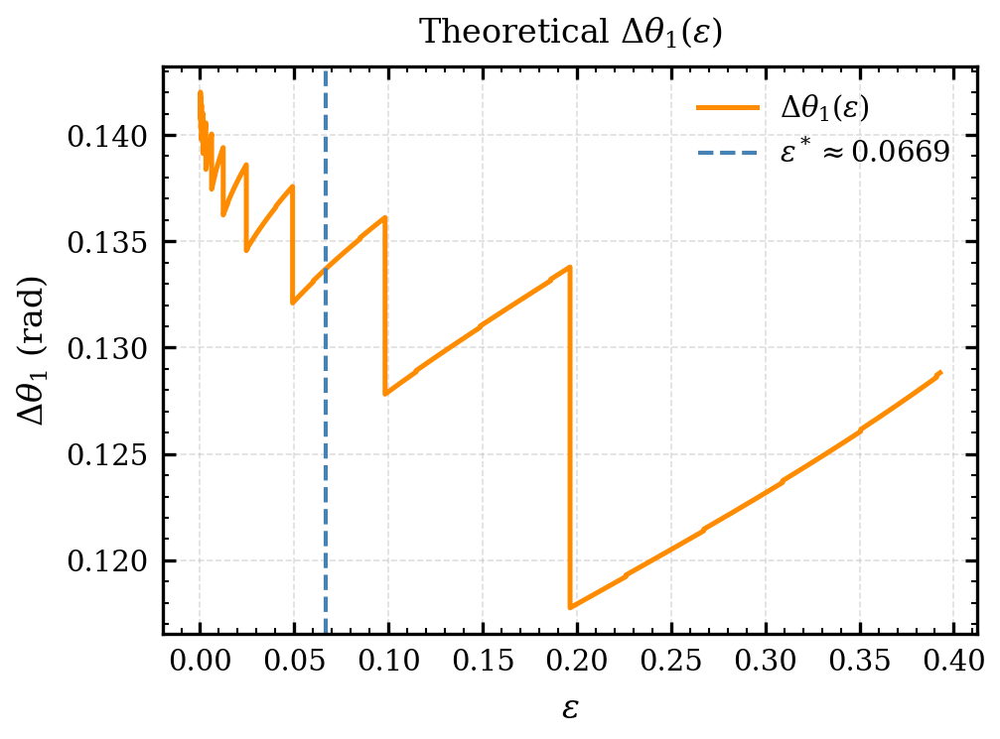

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker
from scipy import stats

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8


plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
})

# ── Parameters ────────────────────────────────────────────────────────────────
alpha = 0.05

# ── Theoretical curves ────────────────────────────────────────────────────────
amplitude = 0.1
def T_theory(eps):
    return np.ceil(np.log2(np.pi / (8 * eps)))

def N_max_CP(eps, alpha=0.05):
    return 69 * np.log((2 / alpha) * np.log2(np.pi / (4 * eps)))

def delta_theta1_CP(eps, a, alpha=0.05):
    T = T_theory(eps)
    N = N_max_CP(eps, alpha)
    
    # Expected number of successes based on the target amplitude
    x = np.round(N * a)
    
    # Per-round significance level
    alpha_round = alpha / T
    
    # Exact Clopper-Pearson bounds for 'a' 
    # (Using scipy.stats.beta.ppf and np.where for array vectorization)
    a_min = np.where(x > 0, stats.beta.ppf(alpha_round / 2.0, x, N - x + 1), 0.0)
    a_max = np.where(x < N, stats.beta.ppf(1.0 - alpha_round / 2.0, x + 1, N - x), 1.0)
        
    # Convert 'a' bounds back to theta bounds (a = sin^2(theta))
    theta_min = np.arcsin(np.sqrt(a_min))
    theta_max = np.arcsin(np.sqrt(a_max))
    
    # Return the full interval width
    return theta_max - theta_min

# ── Dense epsilon grid ────────────────────────────────────────────────────────
eps_dense  = np.linspace(0.0001, np.pi/8, 50000)
dtheta1_th = delta_theta1_CP(eps_dense, a=amplitude, alpha=alpha)

# ── Find ε* where Δθ₁(ε) = 2ε  ───────────────────────────────────────────────
# Define f(ε) = Δθ₁(ε) - 2ε; root is where f changes sign
f = dtheta1_th - 2 * eps_dense

# Detect sign changes
sign_changes = np.where(np.diff(np.sign(f)))[0]

if len(sign_changes) == 0:
    print("No crossing found in the given range.")
    eps_star = None
else:
    # Linear interpolation for a more precise crossing
    idx = sign_changes[0]
    eps_star = eps_dense[idx] - f[idx] * (eps_dense[idx+1] - eps_dense[idx]) / (f[idx+1] - f[idx])
    print(f"ε* (Δθ₁ = 2ε crossing) ≈ {eps_star:.6f} rad")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

# Theoretical curve
ax.plot(eps_dense, dtheta1_th, color='darkorange', label=r'$\Delta\theta_1(\epsilon)$')

# Vertical line at ε*
if eps_star is not None:
    ax.axvline(
        x=eps_star,
        color='steelblue',
        linestyle='--',
        linewidth=1.0,
        label=rf'$\epsilon^* \approx {eps_star:.4f}$'
    )

ax.set_xlabel(r'$\epsilon$')
ax.set_ylabel(r'$\Delta\theta_1$ (rad)')
ax.set_title(r'Theoretical $\Delta\theta_1(\epsilon)$')

ax.legend(fontsize=FONT_SIZE - 1, framealpha=0.7)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker
from scipy import stats

# ── Parameters ────────────────────────────────────────────────────────────────
alpha = 0.05

# ── Theoretical curves ────────────────────────────────────────────────────────
def T_theory(eps):
    return np.ceil(np.log2(np.pi / (8 * eps)))

def N_max_CP(eps, alpha=0.05):
    return 69 * np.log((2 / alpha) * np.log2(np.pi / (4 * eps)))

def delta_theta1_CP(eps, a, alpha=0.05):
    T = T_theory(eps)
    N = N_max_CP(eps, alpha)

    # Expected number of successes based on the target amplitude
    x = np.floor(N * a)

    # Per-round significance level
    alpha_round = alpha / T

    # Exact Clopper-Pearson bounds for 'a'
    a_min = np.where(x > 0, stats.beta.ppf(alpha_round / 2.0, x, N - x + 1), 0.0)
    a_max = np.where(x < N, stats.beta.ppf(1.0 - alpha_round / 2.0, x + 1, N - x), 1.0)

    # Convert 'a' bounds back to theta bounds (a = sin^2(theta))
    theta_min = np.arcsin(np.sqrt(a_min))
    theta_max = np.arcsin(np.sqrt(a_max))

    # Return the full interval width
    return theta_max - theta_min

# ── Dense epsilon grid ────────────────────────────────────────────────────────
eps_dense = np.linspace(0.0001, np.pi / 8, 500000)

# ── Amplitude values ──────────────────────────────────────────────────────────
amplitudes = np.round(np.arange(0.1, 1.0, 0.1), 1)  # [0.1, 0.2, ..., 0.9]

# ── Results storage ───────────────────────────────────────────────────────────
eps_star_results = {}

print(f"{'Amplitude (a)':<20} {'ε* (rad)':<20}")
print("-" * 40)

for amplitude in amplitudes:
    dtheta1_th = delta_theta1_CP(eps_dense, a=amplitude, alpha=alpha)

    # ── Find ε* where Δθ₁(ε) = 2ε ────────────────────────────────────────────
    f = dtheta1_th - 2 * eps_dense

    # Detect sign changes
    sign_changes = np.where(np.diff(np.sign(f)))[0]

    if len(sign_changes) == 0:
        print(f"{amplitude:<20.1f} {'No crossing found':<20}")
        eps_star_results[amplitude] = None
    else:
        # Linear interpolation for a more precise crossing
        idx = sign_changes[0]
        eps_star = eps_dense[idx] - f[idx] * (eps_dense[idx + 1] - eps_dense[idx]) / (f[idx + 1] - f[idx])
        eps_star_results[amplitude] = eps_star
        print(f"{amplitude:<20.1f} {eps_star:<20.6f}")

# ── Summary array ─────────────────────────────────────────────────────────────
eps_star_array = np.array([eps_star_results[a] for a in amplitudes])
print(f"\nε* array: {np.round(eps_star_array, 6)}")

Amplitude (a)        ε* (rad)            
----------------------------------------


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_13844\3079479906.py:25: RuntimeWarning: divide by zero encountered in divide
  alpha_round = alpha / T


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7672\2643895868.py:119: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap(cmap_name, n)


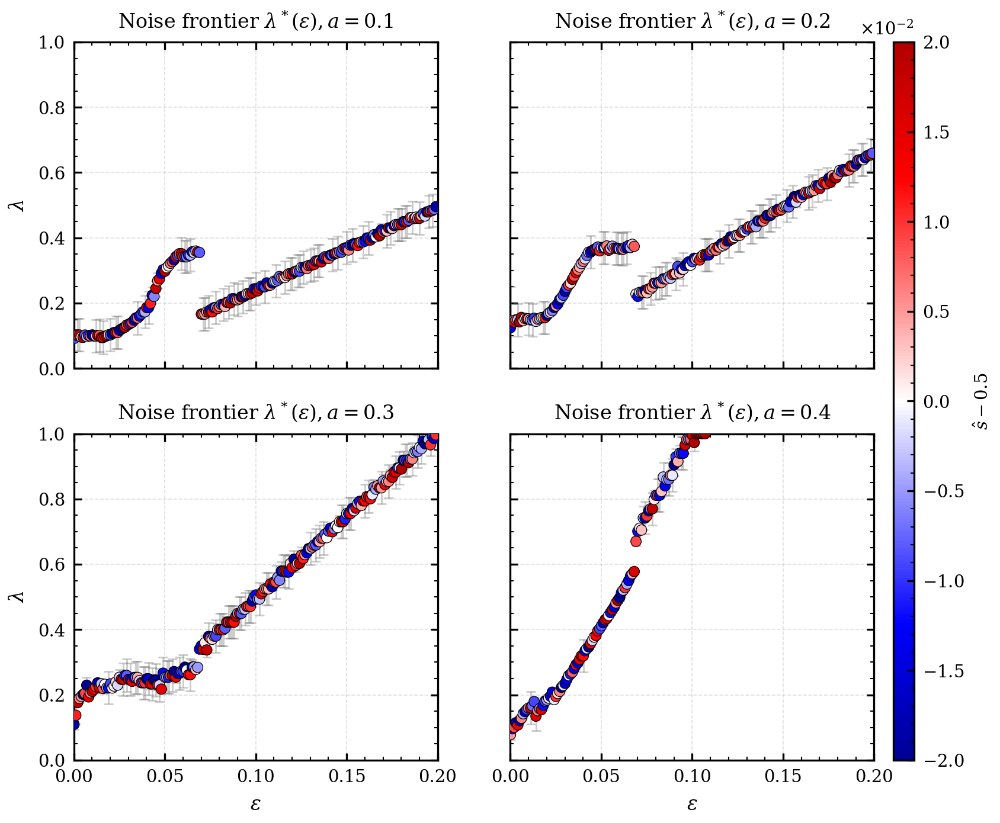

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
import scienceplots
import re

# ── Parse .txt file ───────────────────────────────────────────────────────────
def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts the first 5 columns: epsilon, p_star, uncertainty, s_hat, n_shots
    """
    epsilons      = []
    p_stars       = []
    uncertainties = []
    s_hats        = []
    n_shots       = []

    with open(filepath, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue

        if in_data_section and set(line) <= set("-"):
            continue

        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))
            uncertainties.append(float(parts[2]))
            s_hats.append(float(parts[3]))
            n_shots.append(int(parts[4]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        np.array(uncertainties),
        np.array(s_hats),
        np.array(n_shots),
    )


# ── Load data for all 'a' values ──────────────────────────────────────────────
amplitudes = [0.1, 0.2, 0.3, 0.4]
data_dict = {}
all_delta_s = []

for a in amplitudes:
    filename = f"Data/adaptive_searchCP_Nmax, a = {a}.txt"
    epsilon, p_star, p_uncertainty, s_hat, n_shots = parse_iqae_ceiling_file(filename)
    
    # Filter to epsilon in [0, 0.2] AND exclude lambda >= 1 to prevent colorbar skewing
    mask = (epsilon >= 0.0) & (epsilon <= 0.2) & (p_star < 1.0)
    
    data_dict[a] = {
        'epsilon': epsilon[mask],
        'p_star': p_star[mask],
        'p_uncertainty': p_uncertainty[mask],
        's_hat': s_hat[mask],
        'n_shots': n_shots[mask]
    }
    
    # Collect all delta_s to calculate a global colorbar limit
    all_delta_s.extend(s_hat[mask] - 0.5)

# ── Global success-rate colour limits ─────────────────────────────────────────
all_delta_s = np.array(all_delta_s)
p_lo = np.percentile(all_delta_s, 2)
p_hi = np.percentile(all_delta_s, 98)
clim = max(abs(p_lo), abs(p_hi))


# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'      : (COLUMN_WIDTH_IN * 2, COLUMN_WIDTH_IN * ASPECT_RATIO * 2),
    'figure.dpi'          : 300,
    'text.usetex'         : False,
    'font.family'         : 'serif',
    'font.size'           : FONT_SIZE,
    'axes.labelsize'      : FONT_SIZE,
    'axes.titlesize'      : FONT_SIZE,
    'xtick.labelsize'     : FONT_SIZE - 1,
    'ytick.labelsize'     : FONT_SIZE - 1,
    'lines.linewidth'     : 1.2,
    'axes.linewidth'      : 0.8,
    'axes.grid'           : True,
    'grid.linewidth'      : 0.4,
    'grid.alpha'          : 0.4,
    'grid.linestyle'      : '--',
    'xtick.direction'     : 'in',
    'ytick.direction'     : 'in',
    'xtick.top'           : True,
    'ytick.right'         : True,
    'xtick.major.width'   : 0.8,
    'ytick.major.width'   : 0.8,
    'xtick.minor.visible' : True,
    'ytick.minor.visible' : True,
    'xtick.minor.width'   : 0.5,
    'ytick.minor.width'   : 0.5,
})

# ── Truncated high-contrast colormap ─────────────────────────────────────────
def truncate_cmap(cmap_name, lo=0.10, hi=0.90, n=512):
    base = plt.cm.get_cmap(cmap_name, n)
    cols = base(np.linspace(lo, hi, n))
    return mcolors.LinearSegmentedColormap.from_list(
        f'{cmap_name}_trunc', cols
    )

cmap_contrast = truncate_cmap('seismic', lo=0.10, hi=0.90)


# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axs = plt.subplots(2, 2, sharex=True, sharey=True)

for ax, a in zip(axs.flat, amplitudes):
    # Retrieve filtered data for this amplitude
    eps = data_dict[a]['epsilon']
    p = data_dict[a]['p_star']
    unc = data_dict[a]['p_uncertainty']
    ds = data_dict[a]['s_hat'] - 0.5
    
    # Clamp error bars so they never exceed [0, 1]
    yerr = np.array([
        np.clip(unc, 0, p),           # lower bar can't go below 0
        np.clip(unc, 0, 1.0 - p),     # upper bar can't go above 1
    ])

    # Error bars (drawn first, underneath scatter points)
    ax.errorbar(
        eps, p,
        yerr=yerr,
        fmt='none',
        ecolor='grey',
        alpha=0.4,
        capsize=2.0,
        elinewidth=0.7,
        capthick=0.7,
        zorder=2,
    )

    # Scatter coloured by success rate
    sc = ax.scatter(
        eps, p,
        c=ds,
        cmap=cmap_contrast,
        s=18,
        alpha=1.0,
        linewidths=0.3,
        edgecolors='k',
        vmin=-clim,
        vmax=+clim,
        zorder=3,
    )
    
    ax.set_title(rf'Noise frontier $\lambda^*(\epsilon), a = {a}$')
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

# Enforce limits universally
axs[0, 0].set_xlim(0.0, 0.2)
axs[0, 0].set_ylim(0.0, 1.0)

# Set labels only on the outer edges to reduce clutter
for ax in axs[1, :]:
    ax.set_xlabel(r'$\epsilon$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$\lambda$')


# ── Shared Colorbar ───────────────────────────────────────────────────────────
# Attach the colorbar to the whole figure, drawing space evenly from subplots
cbar = fig.colorbar(sc, ax=axs, pad=0.02, aspect=35)
cbar.set_label(r'$\hat{s} - 0.5$', fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1)

# Scientific notation on colorbar ticks
cbar.ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
cbar.ax.yaxis.get_major_formatter().set_powerlimits((-2, 2))
cbar.ax.yaxis.get_major_formatter().set_scientific(True)
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(-2, 2))

# Zero reference line (mapped to normalised [0,1] colorbar coords)
cbar_zero = (0.0 - (-clim)) / (2 * clim)
cbar.ax.axhline(y=cbar_zero, color='black', linewidth=0.8, linestyle='--')

plt.show()

Weighted constant fit: eps* = 0.068850 +/- 0.000177
Reduced chi^2 = 0.857 (dof = 7)


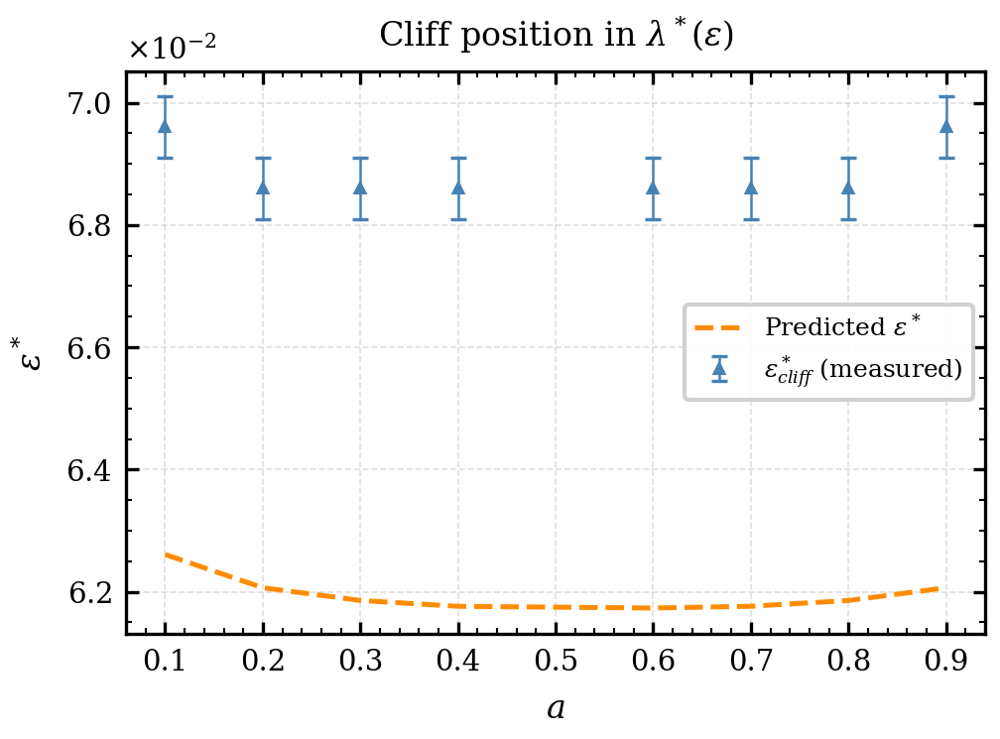

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
})

# ── Data ──────────────────────────────────────────────────────────────────────
a_vals   = np.array([0.1, 0.2, 0.3, 0.4, 0.6, 0.7, 0.8, 0.9])
eps_vals = np.array([0.0696, 0.0686, 0.0686, 0.0686, 0.0686, 0.0686, 0.0686, 0.0696])
eps_err  = np.array([0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005])

predicted = np.array([0.066858, 0.066338, 0.066126, 0.066034, 0.066006, 0.066033, 0.066129, 0.066336,
                      0.066857])

# ── Weighted constant fit ──────────────────────────────────────────────────────
weights       = 1.0 / eps_err**2
eps_const     = np.sum(weights * eps_vals) / np.sum(weights)
eps_const_err = 1.0 / np.sqrt(np.sum(weights))

chi2     = np.sum(((eps_vals - eps_const) / eps_err)**2)
dof      = len(eps_vals) - 1
chi2_red = chi2 / dof

print(f"Weighted constant fit: eps* = {eps_const:.6f} +/- {eps_const_err:.6f}")
print(f"Reduced chi^2 = {chi2_red:.3f} (dof = {dof})")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

ax.errorbar(
    a_vals, eps_vals,
    yerr=eps_err,
    fmt='^',
    color='steelblue',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    zorder=3,
    label=r'$\epsilon^*_{cliff}$ (measured)',
)

# ── Only change: axhline → plot predicted vs a_vals ───────────────────────────
ax.plot(
    a_vals, predicted[:len(a_vals)],  # match lengths
    color='darkorange',
    linestyle='--',
    linewidth=1.2,
    zorder=2,
    label=r'Predicted $\epsilon^*$',
)

ax.set_xlabel(r'$a$')
ax.set_ylabel(r'$\epsilon^*$')
ax.set_title(r'Cliff position in $\lambda^*(\epsilon)$')
ax.legend(fontsize=FONT_SIZE - 2)

# ── Y-axis scientific notation ─────────────────────────────────────────────────
ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax.yaxis.get_major_formatter().set_powerlimits((-2, 2))
ax.ticklabel_format(style='sci', axis='y', scilimits=(-2, 2))

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

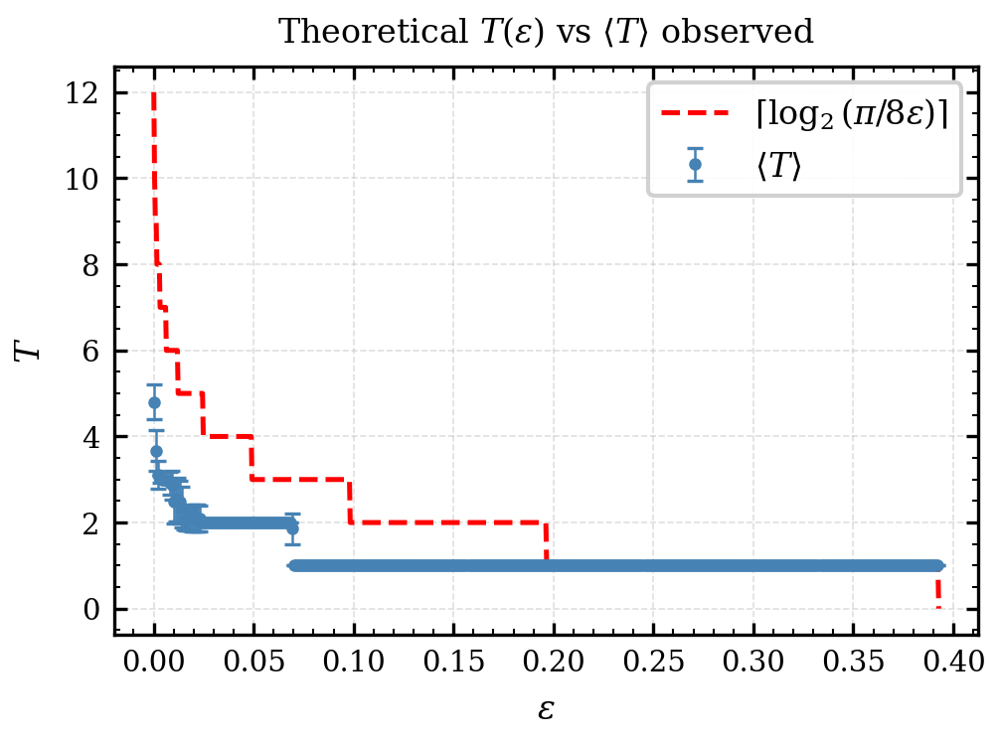

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
})

# ── Load Data ─────────────────────────────────────────────────────────────────
data    = np.load("ceilingsweepCP_Nmax, a = 0.9.npz", allow_pickle=True)
eps_arr = data["epsilon"].astype(float)   # shape: (302000,)
T_arr   = data["T"].astype(float)         # shape: (302000,)

# ── Group by unique epsilon, compute mean & std ───────────────────────────────
unique_eps = np.unique(eps_arr)                          # shape: (302,)
T_mean     = np.array([T_arr[eps_arr == e].mean() for e in unique_eps]) - 1
T_std      = np.array([T_arr[eps_arr == e].std()  for e in unique_eps])

# ── Theoretical curves ────────────────────────────────────────────────────────
eps_grid       = np.linspace(unique_eps.min(), np.pi / 8, 1000)
T_theory       = np.log2(np.pi / (8 * eps_grid))
T_theory_floor = np.ceil(np.log2(np.pi / (8 * eps_grid)))

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()


ax.plot(
    eps_grid, T_theory_floor,
    color='red', linestyle='--',
    label=r'$\lceil\log_2(\pi/8\epsilon)\rceil$'
)

ax.errorbar(
    unique_eps, T_mean,
    yerr=T_std,
    fmt='o',
    color='steelblue',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    label=r'$\langle T \rangle$'
)

ax.set_xlabel(r'$\epsilon$')
ax.set_ylabel(r'$T$')
ax.set_title(r'Theoretical $T(\epsilon)$ vs $\langle T \rangle$ observed')
ax.legend()


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

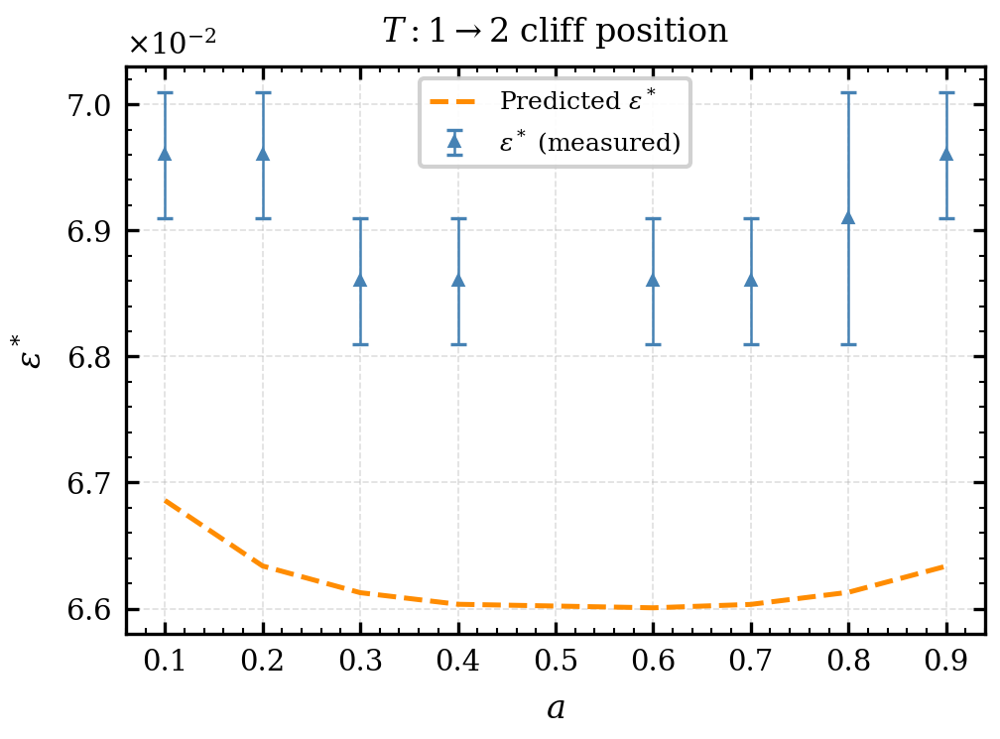

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker
from matplotlib.ticker import ScalarFormatter

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
})

# ── Data ──────────────────────────────────────────────────────────────────────
a_vals   = np.array([0.1, 0.2, 0.3, 0.4, 0.6, 0.7, 0.8, 0.9])
eps_vals = np.array([0.0696, 0.0696, 0.0686, 0.0686, 0.0686, 0.0686, 0.0691, 0.0696])
eps_err  = np.array([0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0010, 0.0005])
predicted = np.array([0.066858, 0.066338, 0.066126, 0.066034, 0.066006, 0.066033, 0.066129, 0.066336,
                      0.066857])



# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

# ── Data points ───────────────────────────────────────────────────────────────
ax.errorbar(
    a_vals, eps_vals,
    yerr=eps_err,
    fmt='^',
    color='steelblue',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    zorder=4,
    label=r'$\epsilon^*$ (measured)',
)

# ── Only change: axhline → plot predicted vs a_vals ───────────────────────────
ax.plot(
    a_vals, predicted[:len(a_vals)],
    color='darkorange',
    linestyle='--',
    linewidth=1.2,
    zorder=2,
    label=r'Predicted $\epsilon^*$',
)

# ── Labels & title ────────────────────────────────────────────────────────────
ax.set_xlabel(r'$a$')
ax.set_ylabel(r'$\epsilon^*$')
ax.set_title(r'$T: 1 \to 2$ cliff position')
ax.legend(fontsize=FONT_SIZE - 2)

# ── Y-axis: force 10^{-2} exponent ────────────────────────────────────────────
formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-2, -2))
ax.yaxis.set_major_formatter(formatter)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7672\3646772861.py:81: RuntimeWarning: divide by zero encountered in divide
  alpha_round = alpha / T


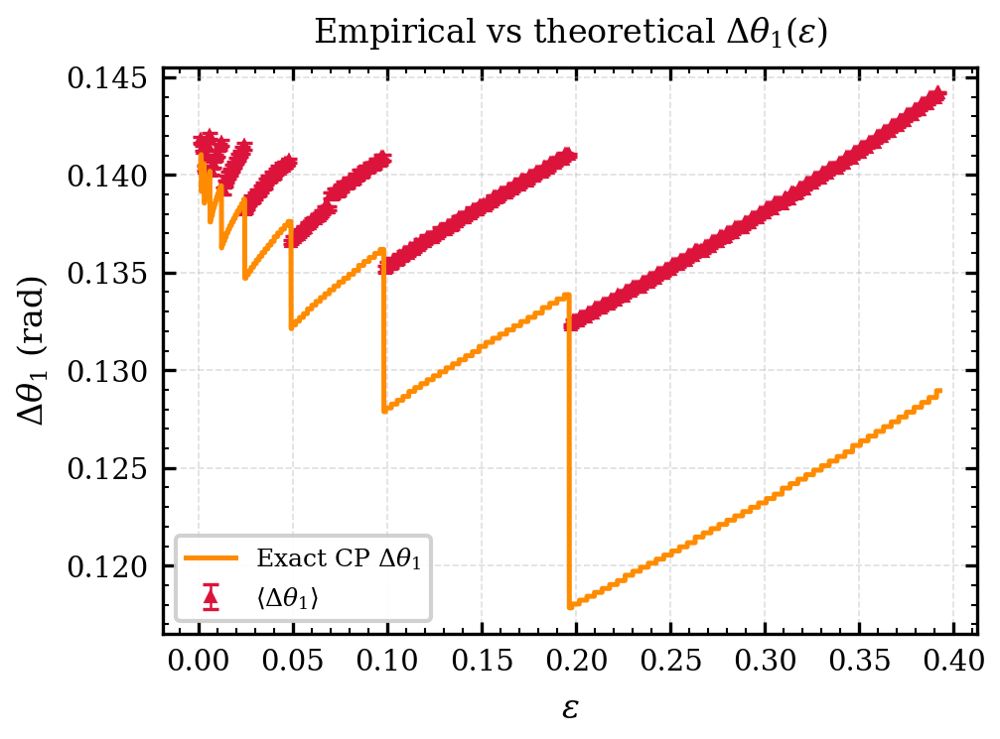

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker
from scipy import stats

amplitude = 0.1######################
# ── Load data ─────────────────────────────────────────────────────────────────
alpha = 0.05

data = np.load(f"Data/ceilingsweepCP_Nmax, a = {amplitude}.npz", allow_pickle=True)
eps_arr              = data["epsilon"]
p_star_arr           = data["p_star"]
T_arr                = data["T"]
K_values_arr         = data["K_values"]
ratios_arr           = data["ratios"]
success_arr          = data["success"]
n_shots_diag_arr     = data["n_shots_diag"]
delta_theta_list_arr = data["delta_theta_list"]

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
})

# ── Theory functions ──────────────────────────────────────────────────────────
def T_theory(eps):
    """Ceiling of T(eps) = ceil(log2(pi / 8*eps))"""
    return np.ceil(np.log2(np.pi / (8.0 * eps)))

def N_max_CP(eps, alpha=0.05):
    """
    Maximum number of shots for canonical phase estimation.
    N_max = floor(69 * ln((2/alpha) * log2(pi / 4*eps)))
    Fully vectorised — works for scalars and arrays.
    """
    raw = 69.0 * np.log((2.0 / alpha) * np.log2(np.pi / (4.0 * eps)))
    return np.floor(raw).astype(int)

def delta_theta1_CP(eps, a, alpha=0.05):
    T = T_theory(eps)
    N = N_max_CP(eps, alpha)
    
    # Expected number of successes based on the target amplitude
    x = np.round(N * a)
    
    # Per-round significance level
    alpha_round = alpha / T
    
    # Exact Clopper-Pearson bounds for 'a' 
    # (Using scipy.stats.beta.ppf and np.where for array vectorization)
    a_min = np.where(x > 0, stats.beta.ppf(alpha_round / 2.0, x, N - x + 1), 0.0)
    a_max = np.where(x < N, stats.beta.ppf(1.0 - alpha_round / 2.0, x + 1, N - x), 1.0)
        
    # Convert 'a' bounds back to theta bounds (a = sin^2(theta))
    theta_min = np.arcsin(np.sqrt(a_min))
    theta_max = np.arcsin(np.sqrt(a_max))
    
    # Return the full interval width
    return theta_max - theta_min

# ── Epsilon bounds ────────────────────────────────────────────────────────────
EPS_MIN = 0.001
EPS_MAX = np.pi / 8.0

# ── Prepare delta_theta[1] data ───────────────────────────────────────────────
eps = np.asarray(eps_arr, dtype=float)

dtheta1 = np.array([
    row[1] * 2 * np.pi if (row is not None and len(row) > 1 and row[1] is not None)
    else np.nan
    for row in delta_theta_list_arr
], dtype=float)

mask_d        = np.isfinite(eps) & np.isfinite(dtheta1) & (eps >= EPS_MIN) & (eps <= EPS_MAX)
eps_d         = eps[mask_d]
dtheta1_valid = dtheta1[mask_d]

# ── Mean/std empirical Delta_theta1 per unique epsilon ────────────────────────
unique_eps   = np.unique(eps_d)
dtheta1_mean = np.array([np.mean(dtheta1_valid[eps_d == e]) for e in unique_eps])
dtheta1_std  = np.array([np.std( dtheta1_valid[eps_d == e]) for e in unique_eps])

# ── Theoretical on dense grid ─────────────────────────────────────────────────
eps_dense  = np.linspace(EPS_MIN, EPS_MAX, 5000)
dtheta1_th = delta_theta1_CP(eps_dense, a = amplitude, alpha=alpha)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

ax.errorbar(
    unique_eps, dtheta1_mean,
    yerr=dtheta1_std,
    fmt='^',
    color='crimson',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    label=r'$\langle\Delta\theta_1\rangle$'
)

ax.plot(
    eps_dense, dtheta1_th,
    '-', color='darkorange', linewidth=1.2, zorder=5,
    # Changed from the Wald formula to explicitly label it as Exact CP
    label=r'Exact CP $\Delta\theta_1$' 
)

ax.set_xlabel(r'$\epsilon$')
ax.set_ylabel(r'$\Delta\theta_1$ (rad)')
ax.set_title(r'Empirical vs theoretical $\Delta\theta_1(\epsilon)$')
ax.legend(fontsize=FONT_SIZE - 2)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

In [34]:
import numpy as np

# ── Compute ratio r(eps) = empirical / theory ─────────────────────────────────
dtheta1_th_at_data = delta_theta1_CP(unique_eps, a = amplitude, alpha=alpha)

r = dtheta1_mean / dtheta1_th_at_data

# ── Global mean & std ─────────────────────────────────────────────────────────
r_mean = np.mean(r)
r_std  = np.std(r)

print("=" * 50)
print(f"  Global ratio r(eps) = <Delta_theta1> / theory")
print("=" * 50)
print(f"  Mean  r  = {r_mean:.4f}")
print(f"  Std   r  = {r_std:.4f}")
print(f"  Min   r  = {np.min(r):.4f}  at eps = {unique_eps[np.argmin(r)]:.5f}")
print(f"  Max   r  = {np.max(r):.4f}  at eps = {unique_eps[np.argmax(r)]:.5f}")
print()

# ── Per-plateau analysis ──────────────────────────────────────────────────────
# Plateaus are defined by constant T = ceil(log2(pi/8*eps))
T_plateau = T_theory(unique_eps).astype(int)
plateaus   = np.unique(T_plateau)

print("=" * 50)
print("  Per-plateau breakdown")
print("=" * 50)
print(f"  {'T':>4}  {'eps_min':>10}  {'eps_max':>10}  {'r_mean':>8}  {'r_std':>8}  {'n_pts':>6}")
print("-" * 50)
for T_val in plateaus:
    mask_p   = T_plateau == T_val
    r_p      = r[mask_p]
    eps_p    = unique_eps[mask_p]
    print(f"  {T_val:>4}  {eps_p.min():>10.5f}  {eps_p.max():>10.5f}"
          f"  {r_p.mean():>8.4f}  {r_p.std():>8.4f}  {len(r_p):>6}")

print()
print(f"  Conclusion: r = {r_mean:.4f} +/- {r_std:.4f}")
print(f"  Theory is a factor ~{1/r_mean:.4f}x tighter than empirical")

  Global ratio r(eps) = <Delta_theta1> / theory
  Mean  r  = 1.0808
  Std   r  = 0.0408
  Min   r  = 1.0091  at eps = 0.00110
  Max   r  = 1.1226  at eps = 0.19710

  Per-plateau breakdown
     T     eps_min     eps_max    r_mean     r_std   n_pts
--------------------------------------------------
     1     0.19710     0.39210    1.1202    0.0012     196
     2     0.09910     0.19610    1.0552    0.0011      98
     3     0.04910     0.09810    1.0343    0.0011      50
     4     0.02510     0.04810    1.0247    0.0010      24
     5     0.01310     0.02410    1.0200    0.0001      12
     6     0.00710     0.01210    1.0158    0.0001       6
     7     0.00310     0.00610    1.0129    0.0001       4
     8     0.00210     0.00210    1.0106    0.0000       1
     9     0.00110     0.00110    1.0091    0.0000       1

  Conclusion: r = 1.0808 +/- 0.0408
  Theory is a factor ~0.9252x tighter than empirical


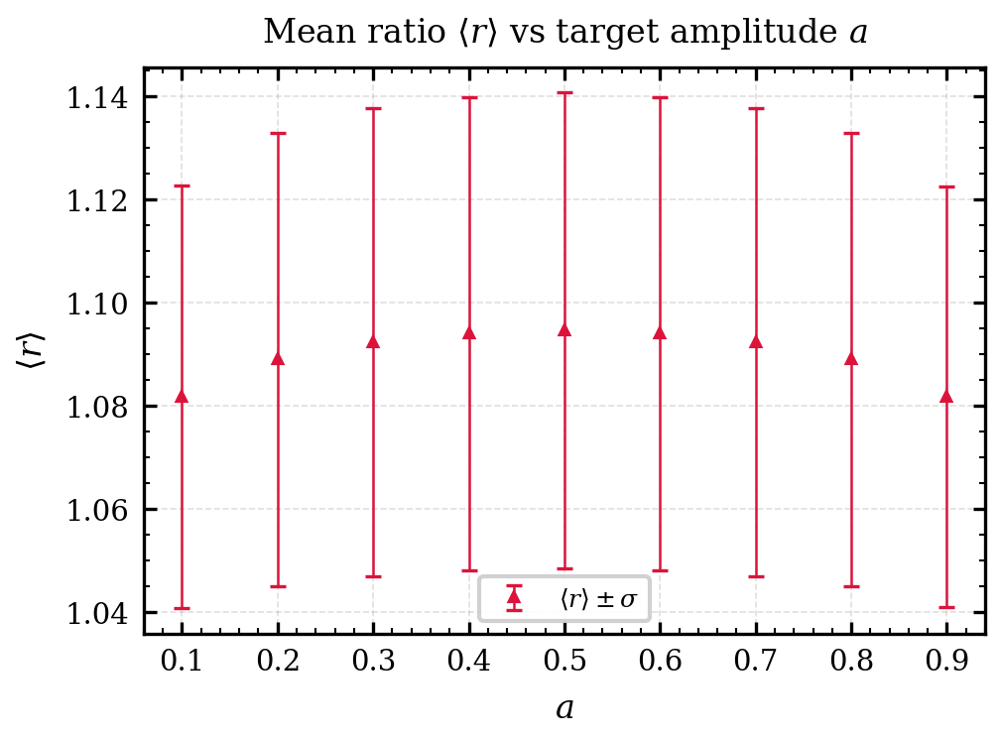

Slope     : -0.000054 ± 0.006833
Intercept : 1.089001 ± 0.003915
chi²      : 0.1120
dof       : 7
chi²_red  : 0.0160


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import matplotlib.ticker as ticker
from scipy import stats

# ── Data ──────────────────────────────────────────────────────────────────────
a      = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])          # 3 points to match mean_r/std_r
mean_r = np.array([1.0818, 1.0890, 1.0924, 1.0940, 1.0946, 1.0940, 1.0924, 1.0890, 1.0818])
std_r  = np.array([0.0409, 0.0440, 0.0453, 0.0459, 0.0461, 0.0459, 0.0453, 0.0440, 0.0408])

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : True,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
})

# ── Weighted linear fit ───────────────────────────────────────────────────────
weights      = 1.0 / std_r**2                          # inverse-variance weights
slope, intercept, *_ = np.polyfit(a, mean_r, 1,        # unweighted fallback
                                   w=weights, full=False) if False else \
               (*np.polyfit(a, mean_r, deg=1, w=weights), )

# Weighted least-squares via scipy for proper chi-square
res          = stats.linregress(a, mean_r)             # for reference
p, cov       = np.polyfit(a, mean_r, 1, w=weights, cov=True)
slope, intercept    = p
slope_err, int_err  = np.sqrt(np.diag(cov))

# ── Chi-square ────────────────────────────────────────────────────────────────
fitted_vals  = slope * a + intercept
residuals    = mean_r - fitted_vals
chi2         = np.sum((residuals / std_r) ** 2)
dof          = len(a) - 2                              # degrees of freedom
chi2_red     = chi2 / dof                              # reduced chi-square

# ── Dense grid for fit line ───────────────────────────────────────────────────
a_dense      = np.linspace(a.min() - 0.02, a.max() + 0.02, 500)
fit_dense    = slope * a_dense + intercept

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

# Data points with error bars
ax.errorbar(
    a, mean_r,
    yerr=std_r,
    fmt='^',
    color='crimson',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    label=r'$\langle r \rangle \pm \sigma$',
    zorder=4
)


ax.set_xlabel(r'$a$')
ax.set_ylabel(r'$\langle r \rangle$')
ax.set_title(r'Mean ratio $\langle r \rangle$ vs target amplitude $a$')
ax.legend(fontsize=FONT_SIZE - 2)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
plt.show()

# ── Print fit summary ─────────────────────────────────────────────────────────
print(f"Slope     : {slope:.6f} ± {slope_err:.6f}")
print(f"Intercept : {intercept:.6f} ± {int_err:.6f}")
print(f"chi²      : {chi2:.4f}")
print(f"dof       : {dof}")
print(f"chi²_red  : {chi2_red:.4f}")

Loaded 'ceilingsweepCP_Nmax, a = 0.1.npz'                      → 69865 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.2.npz'                      → 69521 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.3.npz'                      → 69000 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.4.npz'                      → 69000 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.5.npz'                      → 69000 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.6.npz'                      → 69000 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.7.npz'                      → 69000 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.8.npz'                      → 69503 entries
Loaded 'ceilingsweepCP_Nmax, a = 0.9.npz'                      → 69855 entries

Total K_values[2] entries accumulated: 623744


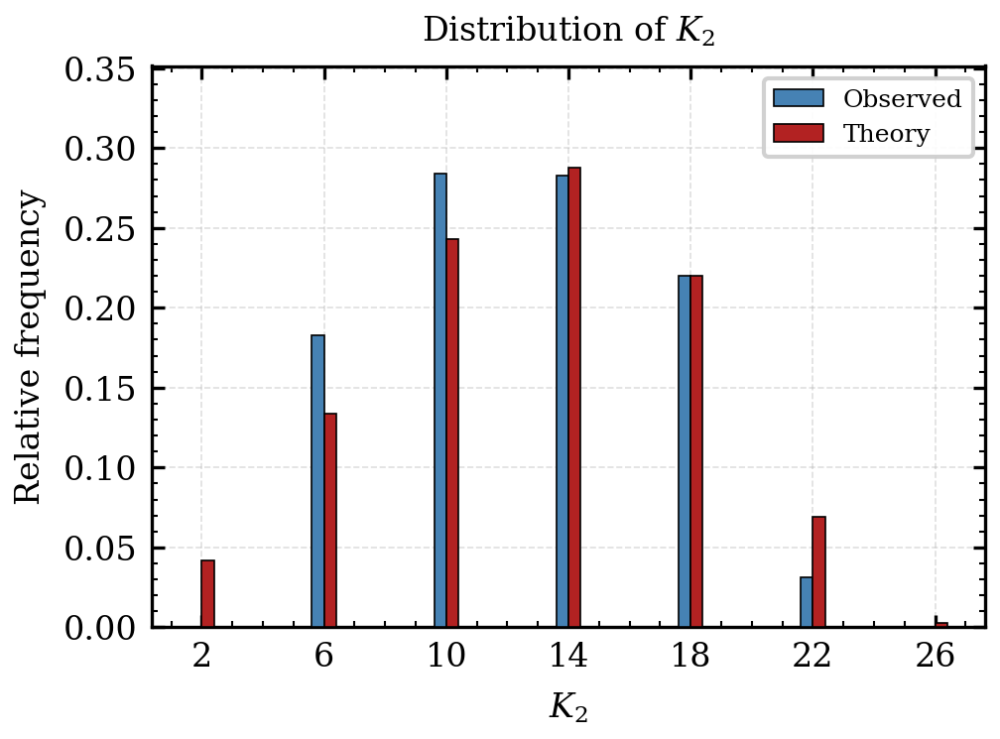

In [87]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from collections import Counter

# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({'text.usetex': False})

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

# ── 1. Define all files ───────────────────────────────────────────────────────
files = [
    "ceilingsweepCP_Nmax, a = 0.1.npz",
    "ceilingsweepCP_Nmax, a = 0.2.npz",
    "ceilingsweepCP_Nmax, a = 0.3.npz",
    "ceilingsweepCP_Nmax, a = 0.4.npz",
    "ceilingsweepCP_Nmax, a = 0.5.npz",
    "ceilingsweepCP_Nmax, a = 0.6.npz",
    "ceilingsweepCP_Nmax, a = 0.7.npz",
    "ceilingsweepCP_Nmax, a = 0.8.npz",
    "ceilingsweepCP_Nmax, a = 0.9.npz",
]

# ── 2. Accumulate K_values[2] across all files ────────────────────────────────
k2_list_all = []

for fpath in files:
    data = np.load(fpath, allow_pickle=True)
    K_values_arr = data["K_values"]

    k2_list = [
        row[2] for row in K_values_arr
        if row is not None and len(row) > 2
    ]
    k2_list_all.extend(k2_list)
    print(f"Loaded {fpath!r:55s} → {len(k2_list):>5d} entries")

print(f"\nTotal K_values[2] entries accumulated: {len(k2_list_all)}")

# ── 3. Count & normalise (observed) ──────────────────────────────────────────
k2_arr = np.array(k2_list_all, dtype=int)
counts = Counter(k2_arr)
total  = len(k2_arr)

k_vals_raw = np.array(sorted(counts.keys()))
k_vals     = k_vals_raw * 2                            # scale K₂ by factor of 2
freqs      = np.array([counts[k // 2] for k in k_vals])
norm       = freqs / total

# ── 4. Theory distribution: ε ∈ [1e-4, π/8], last row ───────────────────────
#    K =  2,    6,     10,    14,    18,    22,    26
theory_K    = np.array([ 2,     6,     10,    14,    18,    22,    26])
theory_norm = np.array([0.042, 0.134, 0.243, 0.288, 0.220, 0.069, 0.003])

# ── 5. Align both distributions on the same K grid ───────────────────────────
all_K  = np.array(sorted(set(k_vals) | set(theory_K)))
obs_map    = dict(zip(k_vals,    norm))
theory_map = dict(zip(theory_K, theory_norm))

obs_aligned    = np.array([obs_map.get(k,    0.0) for k in all_K])
theory_aligned = np.array([theory_map.get(k, 0.0) for k in all_K])

# ── 6. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(
    figsize=(COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO)
)

bar_width = 0.4
offsets   = np.array([-bar_width / 2, +bar_width / 2])

bars_obs = ax.bar(
    all_K + offsets[0], obs_aligned,
    width=bar_width,
    color='steelblue',
    edgecolor='k',
    linewidth=0.4,
    zorder=3,
    label=r'Observed',
)

bars_th = ax.bar(
    all_K + offsets[1], theory_aligned,
    width=bar_width,
    color='firebrick',
    edgecolor='k',
    linewidth=0.4,
    zorder=3,
    label=r'Theory',
)



# ── Labels & formatting ───────────────────────────────────────────────────────
y_max = max(max(obs_aligned), max(theory_aligned))

ax.set_xlabel(r'$K_2$',              fontsize=FONT_SIZE)
ax.set_ylabel(r'Relative frequency', fontsize=FONT_SIZE)
ax.set_title(
    r'Distribution of $K_2$',
    fontsize=FONT_SIZE,
)

ax.set_xticks(all_K)
ax.set_ylim(0, y_max * 1.22)

#ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
#ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.tick_params(direction='in', which='both', top=True, right=True,
               labelsize=FONT_SIZE)

ax.legend(loc='upper right', fontsize=FONT_SIZE - 2, frameon=True)

fig.tight_layout()
plt.show()

In [96]:
import numpy as np
from scipy import stats

# ---- Data ----
N = 623744
K_vals = np.array([2, 6, 10, 14, 18, 22, 26])

obs_freq    = np.array([0.000, 0.182, 0.284, 0.283, 0.220, 0.031, 0.000])
theory_freq = np.array([0.042, 0.134, 0.243, 0.288, 0.220, 0.069, 0.003])

obs_counts = np.round(obs_freq * N).astype(int)

# Rescale theory probabilities so expected counts sum EXACTLY
# to the observed total (removes float/rounding mismatch)
obs_total = obs_counts.sum()
theory_freq_norm = theory_freq / theory_freq.sum()
exp_counts = theory_freq_norm * obs_total

print(f"Observed total: {obs_total}   Expected total: {exp_counts.sum():.6f}")

# ---------------------------------------------------------------
# Pooled bins (merge sparse tails so every E_i >= 5)
# ---------------------------------------------------------------
pooled_labels = ["K<=6", "K=10", "K=14", "K=18", "K>=22"]
obs_pooled = np.array([
    obs_counts[0] + obs_counts[1],
    obs_counts[2],
    obs_counts[3],
    obs_counts[4],
    obs_counts[5] + obs_counts[6],
])
exp_pooled = np.array([
    exp_counts[0] + exp_counts[1],
    exp_counts[2],
    exp_counts[3],
    exp_counts[4],
    exp_counts[5] + exp_counts[6],
])

# Force exact sum match (kills float rounding at ~1e-9 level)
exp_pooled = exp_pooled * (obs_pooled.sum() / exp_pooled.sum())

# ---- Manual chi-square (avoids scipy's strict sum-tolerance check) ----
chi2_stat = np.sum((obs_pooled - exp_pooled) ** 2 / exp_pooled)
df_pooled = len(pooled_labels) - 1
p_pooled = 1 - stats.chi2.cdf(chi2_stat, df_pooled)

print(f"\n[Pooled chi2] chi2 = {chi2_stat:.2f}, df = {df_pooled}, p = {p_pooled:.4g}")
print(f"  min expected count (pooled) = {exp_pooled.min():.1f}  (rule of thumb: >=5)")

for lbl, o, e in zip(pooled_labels, obs_pooled, exp_pooled):
    print(f"  {lbl:<8} obs={o:<8} exp={e:.1f}")

# ---------------------------------------------------------------
# Cramér's V
# ---------------------------------------------------------------
k_pooled = len(pooled_labels)
cramers_v = np.sqrt(chi2_stat / (obs_pooled.sum() * (k_pooled - 1)))
print(f"\nCramér's V = {cramers_v:.4f}")

# ---------------------------------------------------------------
# RMSE on proportions (unpooled)
# ---------------------------------------------------------------
rmse = np.sqrt(np.mean((obs_freq - theory_freq) ** 2))
print(f"RMSE (proportions, unpooled) = {rmse:.4f}")

# ---------------------------------------------------------------
# Signed standardized residuals (unpooled) — rescale exp to obs total
# ---------------------------------------------------------------
exp_counts_unpooled_matched = exp_counts  # already rescaled to obs_total above
resid = (obs_counts - exp_counts_unpooled_matched) / np.sqrt(exp_counts_unpooled_matched)

print(f"\n{'K':<6}{'Residual':<10}")
for k, r in zip(K_vals, resid):
    print(f"{k:<6}{r:<10.2f}")

# ---------------------------------------------------------------
# Monte Carlo exact multinomial p-value (uses the *original* N,
# not the rounded obs_total, since this simulates fresh draws)
# ---------------------------------------------------------------
rng = np.random.default_rng(0)
n_sims = 20000
sim_counts = rng.multinomial(N, theory_freq_norm, size=n_sims)
exp_counts_N = theory_freq_norm * N
sim_chi2 = np.sum((sim_counts - exp_counts_N) ** 2 / exp_counts_N, axis=1)
obs_chi2_unpooled = np.sum((obs_counts - exp_counts_unpooled_matched) ** 2 / exp_counts_unpooled_matched)
p_mc = np.mean(sim_chi2 >= obs_chi2_unpooled)

print(f"\n[Monte Carlo exact test] observed chi2 = {obs_chi2_unpooled:.2f}, "
      f"p = {p_mc:.4g}  (from {n_sims} simulated draws)")

Observed total: 623744   Expected total: 623744.000000

[Pooled chi2] chi2 = 19039.54, df = 4, p = 0
  min expected count (pooled) = 44954.5  (rule of thumb: >=5)
  K<=6     obs=113521   exp=109888.8
  K=10     obs=177143   exp=151721.5
  K=14     obs=176520   exp=179818.1
  K=18     obs=137224   exp=137361.0
  K>=22    obs=19336    exp=44954.5

Cramér's V = 0.0874
RMSE (proportions, unpooled) = 0.0321

K     Residual  
2     -161.94   
6     103.22    
10    65.26     
14    -7.78     
18    -0.37     
22    -114.40   
26    -43.28    

[Monte Carlo exact test] observed chi2 = 56158.42, p = 0  (from 20000 simulated draws)


Loaded 'ceilingsweepCP_Nmax, a = 0.1.npz'                      → 69865 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.2.npz'                      → 139386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.3.npz'                      → 208386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.4.npz'                      → 277386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.5.npz'                      → 346386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.6.npz'                      → 415386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.7.npz'                      → 484386 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.8.npz'                      → 553889 entries so far
Loaded 'ceilingsweepCP_Nmax, a = 0.9.npz'                      → 623744 entries so far

Total entries accumulated: 623744


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_24736\1274127922.py:77: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


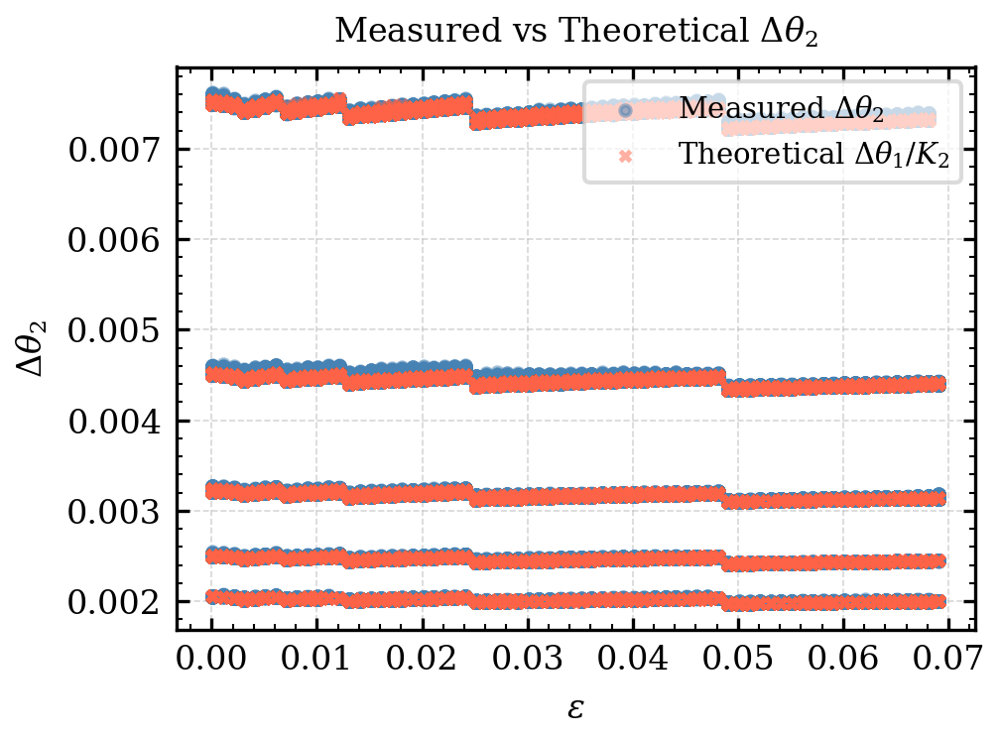

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Define all files ───────────────────────────────────────────────────────
files = [
    "ceilingsweepCP_Nmax, a = 0.1.npz",
    "ceilingsweepCP_Nmax, a = 0.2.npz",
    "ceilingsweepCP_Nmax, a = 0.3.npz",
    "ceilingsweepCP_Nmax, a = 0.4.npz",
    "ceilingsweepCP_Nmax, a = 0.5.npz",
    "ceilingsweepCP_Nmax, a = 0.6.npz",
    "ceilingsweepCP_Nmax, a = 0.7.npz",
    "ceilingsweepCP_Nmax, a = 0.8.npz",
    "ceilingsweepCP_Nmax, a = 0.9.npz",
]

# ── 2. Accumulate across all files ────────────────────────────────────────────
k2_list_all          = []
deltatheta1_list_all = []
deltatheta2_list_all = []
epsilon_list_all     = []

for fpath in files:
    data = np.load(fpath, allow_pickle=True)
    K_values_arr    = data["K_values"]
    dtheta_list_arr = data["delta_theta_list"]
    epsilon_arr     = data["epsilon"]          # ← adjust key name if different

    for k_row, dtheta_row, eps in zip(K_values_arr, dtheta_list_arr, epsilon_arr):
        if k_row is not None and len(k_row) > 2:
            k2_list_all.append(k_row[2])
            deltatheta1_list_all.append(dtheta_row[1])
            deltatheta2_list_all.append(dtheta_row[2])
            epsilon_list_all.append(eps)

    print(f"Loaded {fpath!r:55s} → {len(k2_list_all):>5d} entries so far")

print(f"\nTotal entries accumulated: {len(k2_list_all)}")

# ── 3. Convert to arrays ──────────────────────────────────────────────────────
eps_arr    = np.array(epsilon_list_all)
k2_arr     = np.array(k2_list_all)
dtheta1    = np.array(deltatheta1_list_all)
dtheta2    = np.array(deltatheta2_list_all)

# ── 4. Theoretical prediction ─────────────────────────────────────────────────
dtheta2_theoretical = dtheta1 / k2_arr

# ── 5. Sort by epsilon for clean line plots ───────────────────────────────────
sort_idx   = np.argsort(eps_arr)
eps_sorted = eps_arr[sort_idx]
theo_sorted = dtheta2_theoretical[sort_idx]
meas_sorted = dtheta2[sort_idx]

# ── 6. Plot ───────────────────────────────────────────────────────────────────
COLUMN_WIDTH_IN = 3.5
FONT_SIZE       = 8

fig, ax = plt.subplots(figsize=(COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * 3/4))

ax.scatter(eps_sorted, meas_sorted,
           s=6, alpha=0.5, color="steelblue",
           label=r"Measured $\Delta\theta_2$", zorder=3)

ax.scatter(eps_sorted, theo_sorted,
           s=6, alpha=0.5, color="tomato",
           marker="x",
           label=r"Theoretical $\Delta\theta_1 / K_2$", zorder=3)

ax.set_xlabel(r"$\epsilon$",        fontsize=FONT_SIZE)
ax.set_ylabel(r"$\Delta\theta_2$",  fontsize=FONT_SIZE)
ax.set_title(r"Measured vs Theoretical $\Delta\theta_2$", fontsize=FONT_SIZE)
ax.tick_params(labelsize=FONT_SIZE)
ax.legend(fontsize=FONT_SIZE - 1, framealpha=0.7)
ax.grid(True, linewidth=0.4, alpha=0.5)

fig.tight_layout()
plt.show()

In [97]:
# ══════════════════════════════════════════════════════════════════════════
#  STATISTICAL TESTS — run after the accumulation/plotting cell above
#  H0 (mechanistic claim): Delta theta_2 = Delta theta_1 / K_2   (Eq. sigma_K)
# ══════════════════════════════════════════════════════════════════════════

import numpy as np
from scipy import stats

pred = dtheta2_theoretical.copy()   # Delta theta_1 / K_2
meas = dtheta2.copy()               # measured Delta theta_2

mask = (pred > 0) & (meas > 0) & np.isfinite(pred) & np.isfinite(meas)
pred = pred[mask]
meas = meas[mask]
n    = len(pred)

print(f"n = {n} paired points used in tests\n")

# ---------------------------------------------------------------
# Test 1: Paired ratio test
#   r_i = meas_i / pred_i,   H0: E[r] = 1
# ---------------------------------------------------------------
ratio = meas / pred

t_stat, p_ttest    = stats.ttest_1samp(ratio, popmean=1.0)
w_stat, p_wilcoxon = stats.wilcoxon(ratio - 1.0)

print("[Test 1: Paired ratio, meas/pred]")
print(f"  mean(ratio)   = {ratio.mean():.4f}")
print(f"  median(ratio) = {np.median(ratio):.4f}")
print(f"  std(ratio)    = {ratio.std():.4f}")
print(f"  one-sample t-test    H0: E[ratio]=1      -> t={t_stat:.3f}, p={p_ttest:.4g}")
print(f"  Wilcoxon signed-rank H0: median(ratio)=1 -> W={w_stat:.3f}, p={p_wilcoxon:.4g}")

# ---------------------------------------------------------------
# Test 2: OLS regression, meas ~ pred
#   H0a: slope = 1      H0b: intercept = 0
# ---------------------------------------------------------------
slope, intercept, r_value, p_slope_raw, se_slope = stats.linregress(pred, meas)

x_mean       = pred.mean()
resid        = meas - (intercept + slope * pred)
s_err        = np.sqrt(np.sum(resid**2) / (n - 2))
se_intercept = s_err * np.sqrt(1/n + x_mean**2 / np.sum((pred - x_mean)**2))

t_slope_eq1 = (slope - 1) / se_slope
p_slope_eq1 = 2 * (1 - stats.t.cdf(abs(t_slope_eq1), n - 2))

t_int_eq0 = intercept / se_intercept
p_int_eq0 = 2 * (1 - stats.t.cdf(abs(t_int_eq0), n - 2))

print("\n[Test 2: OLS regression, measured ~ predicted]")
print(f"  slope     = {slope:.4f}  (se={se_slope:.4f})")
print(f"  intercept = {intercept:.6f}  (se={se_intercept:.6f})")
print(f"  R^2       = {r_value**2:.4f}")
print(f"  H0: slope=1      -> t={t_slope_eq1:.3f}, p={p_slope_eq1:.4g}")
print(f"  H0: intercept=0  -> t={t_int_eq0:.3f}, p={p_int_eq0:.4g}")

# ---------------------------------------------------------------
# Descriptive error metrics (companions, not stand-alone tests)
# ---------------------------------------------------------------
rmse = np.sqrt(np.mean((meas - pred) ** 2))
mape = np.mean(np.abs((meas - pred) / pred)) * 100

print("\n[Descriptive]")
print(f"  RMSE = {rmse:.6f}")
print(f"  MAPE = {mape:.3f}%")

# ══════════════════════════════════════════════════════════════════════════
#  UNCERTAINTY ON THE MEAN RATIO
# ══════════════════════════════════════════════════════════════════════════

sem_ratio = ratio.std(ddof=1) / np.sqrt(n)          # standard error of the mean
ci95_lo, ci95_hi = stats.t.interval(
    0.95, df=n - 1, loc=ratio.mean(), scale=sem_ratio
)

print("[Uncertainty on mean ratio]")
print(f"  mean(ratio)       = {ratio.mean():.6f}")
print(f"  SEM               = {sem_ratio:.6f}")
print(f"  mean +/- SEM      = {ratio.mean():.4f} +/- {sem_ratio:.4f}")
print(f"  95% CI            = [{ci95_lo:.6f}, {ci95_hi:.6f}]")

# same for the OLS slope, using the se already computed by linregress
slope_ci_lo, slope_ci_hi = (
    slope - stats.t.ppf(0.975, n - 2) * se_slope,
    slope + stats.t.ppf(0.975, n - 2) * se_slope,
)
print(f"\n[Uncertainty on OLS slope]")
print(f"  slope +/- se      = {slope:.4f} +/- {se_slope:.4f}")
print(f"  95% CI            = [{slope_ci_lo:.6f}, {slope_ci_hi:.6f}]")

n = 623744 paired points used in tests

[Test 1: Paired ratio, meas/pred]
  mean(ratio)   = 1.0027
  median(ratio) = 1.0022
  std(ratio)    = 0.0044
  one-sample t-test    H0: E[ratio]=1      -> t=490.828, p=0
  Wilcoxon signed-rank H0: median(ratio)=1 -> W=33903477150.000, p=0

[Test 2: OLS regression, measured ~ predicted]
  slope     = 1.0058  (se=0.0000)
  intercept = -0.000011  (se=0.000000)
  R^2       = 0.9999
  H0: slope=1      -> t=427.614, p=0
  H0: intercept=0  -> t=-176.040, p=0

[Descriptive]
  RMSE = 0.000025
  MAPE = 0.389%
[Uncertainty on mean ratio]
  mean(ratio)       = 1.002743
  SEM               = 0.000006
  mean +/- SEM      = 1.0027 +/- 0.0000
  95% CI            = [1.002732, 1.002754]

[Uncertainty on OLS slope]
  slope +/- se      = 1.0058 +/- 0.0000
  95% CI            = [1.005754, 1.005807]


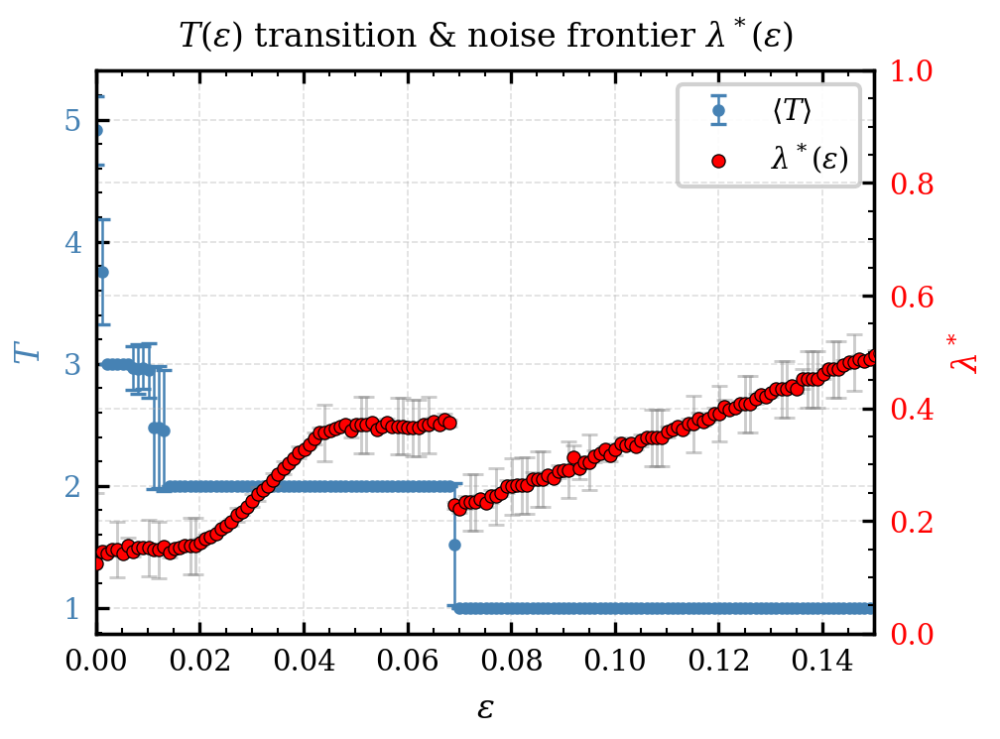

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import scienceplots
import re

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'        : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'            : 300,
    'text.usetex'           : False,
    'font.family'           : 'serif',
    'font.size'             : FONT_SIZE,
    'axes.labelsize'        : FONT_SIZE,
    'axes.titlesize'        : FONT_SIZE,
    'xtick.labelsize'       : FONT_SIZE - 1,
    'ytick.labelsize'       : FONT_SIZE - 1,
    'lines.linewidth'       : 1.2,
    'axes.linewidth'        : 0.8,
    'axes.grid'             : True,
    'grid.linewidth'        : 0.4,
    'grid.alpha'            : 0.4,
    'grid.linestyle'        : '--',
    'xtick.direction'       : 'in',
    'ytick.direction'       : 'in',
    'xtick.top'             : True,
    'ytick.right'           : False,
    'xtick.major.width'     : 0.8,
    'ytick.major.width'     : 0.8,
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,
    'xtick.minor.width'     : 0.5,
    'ytick.minor.width'     : 0.5,
    'legend.frameon'        : True,
    'legend.framealpha'     : 0.9,
    'legend.edgecolor'      : '0.8',
    'legend.fontsize'       : FONT_SIZE - 1,
})

# ── Load T data ───────────────────────────────────────────────────────────────
data    = np.load("Data/ceilingsweepCP_Nmax, a = 0.2.npz", allow_pickle=True)
eps_arr = data["epsilon"].astype(float)
T_arr   = data["T"].astype(float)

unique_eps = np.unique(eps_arr)
T_mean     = np.array([T_arr[eps_arr == e].mean() for e in unique_eps]) - 1
T_std      = np.array([T_arr[eps_arr == e].std()  for e in unique_eps])

# ── Load λ* data ──────────────────────────────────────────────────────────────
def parse_iqae_ceiling_file(filepath):
    epsilons, p_stars, uncertainties = [], [], []
    with open(filepath, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()
    in_data_section = False
    for line in lines:
        line = line.strip()
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue
        if in_data_section and set(line) <= set("-"):
            continue
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))
            uncertainties.append(float(parts[2]))
    return np.array(epsilons), np.array(p_stars), np.array(uncertainties)

epsilon, p_star, p_uncertainty = parse_iqae_ceiling_file(
    "Data/adaptive_searchCP_Nmax, a = 0.2.txt"
)

# Clamp error bars to [0, 1]
yerr_lambda = np.array([
    np.clip(p_uncertainty, 0, p_star),
    np.clip(p_uncertainty, 0, 1.0 - p_star),
])

# ── Figure with twin y-axes ───────────────────────────────────────────────────
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

# ── Left axis: ⟨T⟩ ───────────────────────────────────────────────────────────
ax1.errorbar(
    unique_eps, T_mean,
    yerr=T_std,
    fmt='o',
    color='steelblue',
    markersize=2.0,
    linewidth=0.8,
    capsize=2.0,
    capthick=0.8,
    elinewidth=0.6,
    label=r'$\langle T \rangle$',
    zorder=3,
)
ax1.set_xlabel(r'$\epsilon$')
ax1.set_ylabel(r'$T$', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue', direction='in')
ax1.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax1.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax1.set_xlim(0.0, 0.15)                          # ← x-axis range

# ── Right axis: λ* frontier ───────────────────────────────────────────────────
ax2.errorbar(
    epsilon, p_star,
    yerr=yerr_lambda,
    fmt='none',
    ecolor='grey',
    alpha=0.4,
    capsize=2.0,
    elinewidth=0.7,
    capthick=0.7,
    zorder=2,
)
ax2.scatter(
    epsilon, p_star,
    color='red',                                  # ← frontier colour
    s=10,
    linewidths=0.3,
    edgecolors='k',
    zorder=3,
    label=r'$\lambda^*(\epsilon)$',
)
ax2.set_ylabel(r'$\lambda^*$', color='red')       # ← axis label colour
ax2.tick_params(axis='y', labelcolor='red', direction='in')
ax2.set_ylim(0.0, 1.0)
ax2.yaxis.set_minor_locator(ticker.AutoMinorLocator())

# ── Combined legend ───────────────────────────────────────────────────────────
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    handles1 + handles2,
    labels1  + labels2,
    loc='best',
)

ax1.set_title(r'$T(\epsilon)$ transition & noise frontier $\lambda^*(\epsilon)$')

fig.tight_layout()
plt.show()